In [1]:
!pip install -q scikit-learn pandas numpy matplotlib seaborn joblib tqdm

In [2]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

from sklearn.pipeline import Pipeline

RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
# ============================================================
# 2. CONFIGURATION
# ============================================================

PROJECT_DIR = (
    "/content/drive/MyDrive/EEE6778_Semester_Project"
)

DATASET_PATH = os.path.join(
    PROJECT_DIR,
    "BLIP_generated_dataset.csv"
)

OUTPUT_DIR = os.path.join(
    PROJECT_DIR,
    "tfidf_logistic_regression"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

# Dataset split
VALIDATION_SIZE = 0.20

# TF-IDF parameters
MAX_FEATURES = 50000
NGRAM_RANGE = (1, 2)
MIN_DF = 1
MAX_DF = 0.95

# Logistic regression parameters
C_VALUE = 1.0
MAX_ITER = 2000
CLASS_WEIGHT = "balanced"

print("Dataset:", DATASET_PATH)
print("Output directory:", OUTPUT_DIR)

Dataset: /content/drive/MyDrive/EEE6778_Semester_Project/BLIP_generated_dataset.csv
Output directory: /content/drive/MyDrive/EEE6778_Semester_Project/tfidf_logistic_regression


In [9]:
# ============================================================
# 3. LOAD DATASET
# ============================================================

df = pd.read_csv(DATASET_PATH)

print("Original dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

# ------------------------------------------------------------
# VERIFY REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "image_path",
    "alt_text",
    "label"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# ------------------------------------------------------------
# CLEAN DATA
# ------------------------------------------------------------

df["alt_text"] = (
    df["alt_text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

df["image_path"] = (
    df["image_path"]
    .fillna("")
    .astype(str)
    .str.strip()
)

df["label"] = pd.to_numeric(
    df["label"],
    errors="coerce"
)

df = df.dropna(
    subset=["label"]
).copy()

df["label"] = df["label"].astype(int)

# Keep only valid binary labels.
df = df[
    df["label"].isin([0, 1])
].copy()

# Remove rows without captions or image paths.
df = df[
    (df["alt_text"] != "") &
    (df["image_path"] != "")
].copy()

# Check image paths.
df = df[
    df["image_path"].apply(os.path.isfile)
].copy()

df = df.reset_index(drop=True)

# ------------------------------------------------------------
# VERIFY DATASET
# ------------------------------------------------------------

print("\nCleaned dataset shape:", df.shape)

print("\nLabel distribution:")
print(df["label"].value_counts())

print("\nLabel proportions:")
print(df["label"].value_counts(normalize=True))

print("\nSample records:")
display(
    df[
        ["image_path", "alt_text", "label"]
    ].head()
)

if df["label"].nunique() != 2:
    raise ValueError(
        "Dataset must contain both positive (1) "
        "and negative (0) examples."
    )

if len(df) == 0:
    raise ValueError(
        "No valid dataset rows remain after cleaning."
    )

Original dataset shape: (2002, 9)

Columns:
['document_id', 'page_id', 'figure_id', 'image_path', 'alt_text', 'label', 'pair_type', 'caption_source_image_path', 'caption_source_image_id']

Cleaned dataset shape: (2002, 9)

Label distribution:
label
1    1001
0    1001
Name: count, dtype: int64

Label proportions:
label
1    0.5
0    0.5
Name: proportion, dtype: float64

Sample records:


,image_path,alt_text,label
0,/content/drive/MyDrive/EEE6778_Semester_Projec...,an aerial view of a bridge over a body of water,1
1,/content/drive/MyDrive/EEE6778_Semester_Projec...,a black and white photo of a smiling man,0
2,/content/drive/MyDrive/EEE6778_Semester_Projec...,the signature of a man in blue ink on a white ...,1
3,/content/drive/MyDrive/EEE6778_Semester_Projec...,"a table with two columns, one column and one c...",1
4,/content/drive/MyDrive/EEE6778_Semester_Projec...,a pie pie pie pie pie pie pie pie pie pie pie ...,1


In [10]:
# ============================================================
# 4. TRAIN / VALIDATION SPLIT
# ============================================================

if "document_id" in df.columns:

    document_groups = (
        df["document_id"]
        .fillna("")
        .astype(str)
        .str.strip()
    )

else:

    document_groups = pd.Series(
        [""] * len(df),
        index=df.index
    )

# Use document groups when there is more than one
# meaningful document ID.
valid_documents = (
    document_groups != ""
).sum()

unique_documents = document_groups[
    document_groups != ""
].nunique()

if unique_documents >= 2:

    groups = document_groups

    split_type = "Document-level split"

else:

    # Fallback: keep all pairs for an image together.
    groups = df["image_path"]

    split_type = "Image-level split"

print("Split strategy:", split_type)
print("Number of groups:", groups.nunique())

# ------------------------------------------------------------
# GROUP SHUFFLE SPLIT
# ------------------------------------------------------------

splitter = GroupShuffleSplit(
    n_splits=50,
    test_size=VALIDATION_SIZE,
    random_state=RANDOM_SEED
)

train_indices = None
val_indices = None

for candidate_train, candidate_val in splitter.split(
    df,
    df["label"],
    groups=groups
):

    candidate_train_labels = set(
        df.iloc[candidate_train]["label"].unique()
    )

    candidate_val_labels = set(
        df.iloc[candidate_val]["label"].unique()
    )

    if (
        candidate_train_labels == {0, 1}
        and candidate_val_labels == {0, 1}
    ):

        train_indices = candidate_train
        val_indices = candidate_val

        break

if train_indices is None:

    raise ValueError(
        "Could not create a group split containing "
        "both classes in training and validation. "
        "Check your document IDs and label distribution."
    )

train_df = df.iloc[train_indices].copy()
val_df = df.iloc[val_indices].copy()

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

# ------------------------------------------------------------
# VERIFY SPLIT
# ------------------------------------------------------------

print("\nTraining shape:", train_df.shape)
print("Validation shape:", val_df.shape)

print("\nTraining label distribution:")
print(train_df["label"].value_counts())

print("\nValidation label distribution:")
print(val_df["label"].value_counts())

train_groups = set(groups.iloc[train_indices])
val_groups = set(groups.iloc[val_indices])

overlapping_groups = train_groups.intersection(
    val_groups
)

print("\nOverlapping groups:", len(overlapping_groups))

assert len(overlapping_groups) == 0

print("\nTrain/validation split completed successfully.")

Split strategy: Image-level split
Number of groups: 1001

Training shape: (1600, 9)
Validation shape: (402, 9)

Training label distribution:
label
1    800
0    800
Name: count, dtype: int64

Validation label distribution:
label
1    201
0    201
Name: count, dtype: int64

Overlapping groups: 0

Train/validation split completed successfully.


In [11]:
# ============================================================
# 5. TF-IDF VECTORIZATION
# ============================================================

X_train_text = train_df["alt_text"].values
X_val_text = val_df["alt_text"].values

y_train = train_df["label"].values
y_val = val_df["label"].values

# ------------------------------------------------------------
# INITIALIZE TF-IDF VECTORIZER
# ------------------------------------------------------------

tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    stop_words="english",
    ngram_range=NGRAM_RANGE,
    max_features=MAX_FEATURES,
    min_df=MIN_DF,
    max_df=MAX_DF,
    sublinear_tf=True,
    norm="l2"
)

# ------------------------------------------------------------
# FIT ON TRAINING DATA ONLY
# ------------------------------------------------------------

X_train_tfidf = tfidf_vectorizer.fit_transform(
    X_train_text
)

X_val_tfidf = tfidf_vectorizer.transform(
    X_val_text
)

print("TF-IDF vectorization complete.")

print("\nTraining feature shape:", X_train_tfidf.shape)
print("Validation feature shape:", X_val_tfidf.shape)

print(
    "\nNumber of vocabulary terms:",
    len(tfidf_vectorizer.vocabulary_)
)

TF-IDF vectorization complete.

Training feature shape: (1600, 2242)
Validation feature shape: (402, 2242)

Number of vocabulary terms: 2242


In [12]:
# ============================================================
# 6. TRAIN LOGISTIC REGRESSION
# ============================================================

logistic_model = LogisticRegression(
    C=C_VALUE,
    max_iter=MAX_ITER,
    class_weight=CLASS_WEIGHT,
    random_state=RANDOM_SEED,
    solver="liblinear"
)

# ------------------------------------------------------------
# TRAIN MODEL
# ------------------------------------------------------------

print("Training Logistic Regression...")

logistic_model.fit(
    X_train_tfidf,
    y_train
)

print("\nTraining complete.")

# ------------------------------------------------------------
# TRAINING PERFORMANCE
# ------------------------------------------------------------

train_predictions = logistic_model.predict(
    X_train_tfidf
)

train_probabilities = logistic_model.predict_proba(
    X_train_tfidf
)[:, 1]

train_accuracy = accuracy_score(
    y_train,
    train_predictions
)

train_f1 = f1_score(
    y_train,
    train_predictions,
    zero_division=0
)

print("\nTraining Results")
print("---------------------------")
print(f"Accuracy: {train_accuracy:.4f}")
print(f"F1-score: {train_f1:.4f}")

Training Logistic Regression...

Training complete.

Training Results
---------------------------
Accuracy: 0.6863
F1-score: 0.6913


In [13]:
# ============================================================
# 7. VALIDATION EVALUATION
# ============================================================

# ------------------------------------------------------------
# PREDICTIONS
# ------------------------------------------------------------

val_predictions = logistic_model.predict(
    X_val_tfidf
)

val_probabilities = logistic_model.predict_proba(
    X_val_tfidf
)[:, 1]

# ------------------------------------------------------------
# CLASSIFICATION METRICS
# ------------------------------------------------------------

val_accuracy = accuracy_score(
    y_val,
    val_predictions
)

val_precision = precision_score(
    y_val,
    val_predictions,
    zero_division=0
)

val_recall = recall_score(
    y_val,
    val_predictions,
    zero_division=0
)

val_f1 = f1_score(
    y_val,
    val_predictions,
    zero_division=0
)

val_roc_auc = roc_auc_score(
    y_val,
    val_probabilities
)

# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

metrics = {
    "Accuracy": val_accuracy,
    "Precision": val_precision,
    "Recall": val_recall,
    "F1-score": val_f1,
    "ROC-AUC": val_roc_auc
}

print("\nVALIDATION RESULTS")
print("=" * 45)

for metric_name, metric_value in metrics.items():

    print(
        f"{metric_name}: {metric_value:.4f}"
    )

print("=" * 45)

# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report:")

print(
    classification_report(
        y_val,
        val_predictions,
        target_names=[
            "Nonmeaningful",
            "Meaningful"
        ],
        zero_division=0
    )
)


VALIDATION RESULTS
Accuracy: 0.3557
Precision: 0.3606
Recall: 0.3731
F1-score: 0.3667
ROC-AUC: 0.3185

Classification Report:
               precision    recall  f1-score   support

Nonmeaningful       0.35      0.34      0.34       201
   Meaningful       0.36      0.37      0.37       201

     accuracy                           0.36       402
    macro avg       0.36      0.36      0.36       402
 weighted avg       0.36      0.36      0.36       402



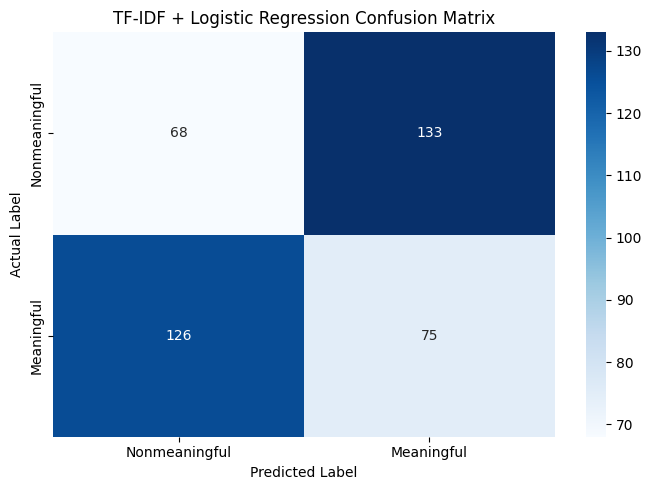

In [14]:
# ============================================================
# 8. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_val,
    val_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Nonmeaningful",
        "Meaningful"
    ],
    yticklabels=[
        "Nonmeaningful",
        "Meaningful"
    ]
)

plt.title("TF-IDF + Logistic Regression Confusion Matrix")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

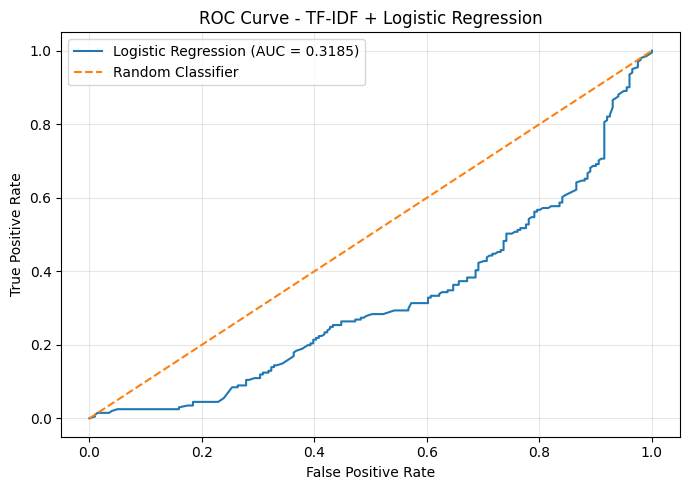

In [15]:
# ============================================================
# 9. ROC CURVE
# ============================================================

fpr, tpr, thresholds = roc_curve(
    y_val,
    val_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {val_roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - TF-IDF + Logistic Regression")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "roc_curve.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Top features associated with MEANINGFUL captions:


,Feature,Coefficient
0,posing,0.615275
1,image man,0.573730
2,tie glasses,0.550406
3,walking street,0.535909
4,working,0.531454
5,field,0.503008
6,script,0.500004
7,handwritten script,0.500004
8,line,0.499488
9,pie chart,0.493702



Top features associated with NONMEANINGFUL captions:


,Feature,Coefficient
0,logo fundraiser,-0.795640
1,fundraiser,-0.795640
2,graph showing,-0.758590
3,tie standing,-0.727265
4,cnn,-0.670015
5,cnn logo,-0.670015
6,standing people,-0.636215
7,number,-0.590952
8,best logo,-0.588511
9,earth best,-0.588511


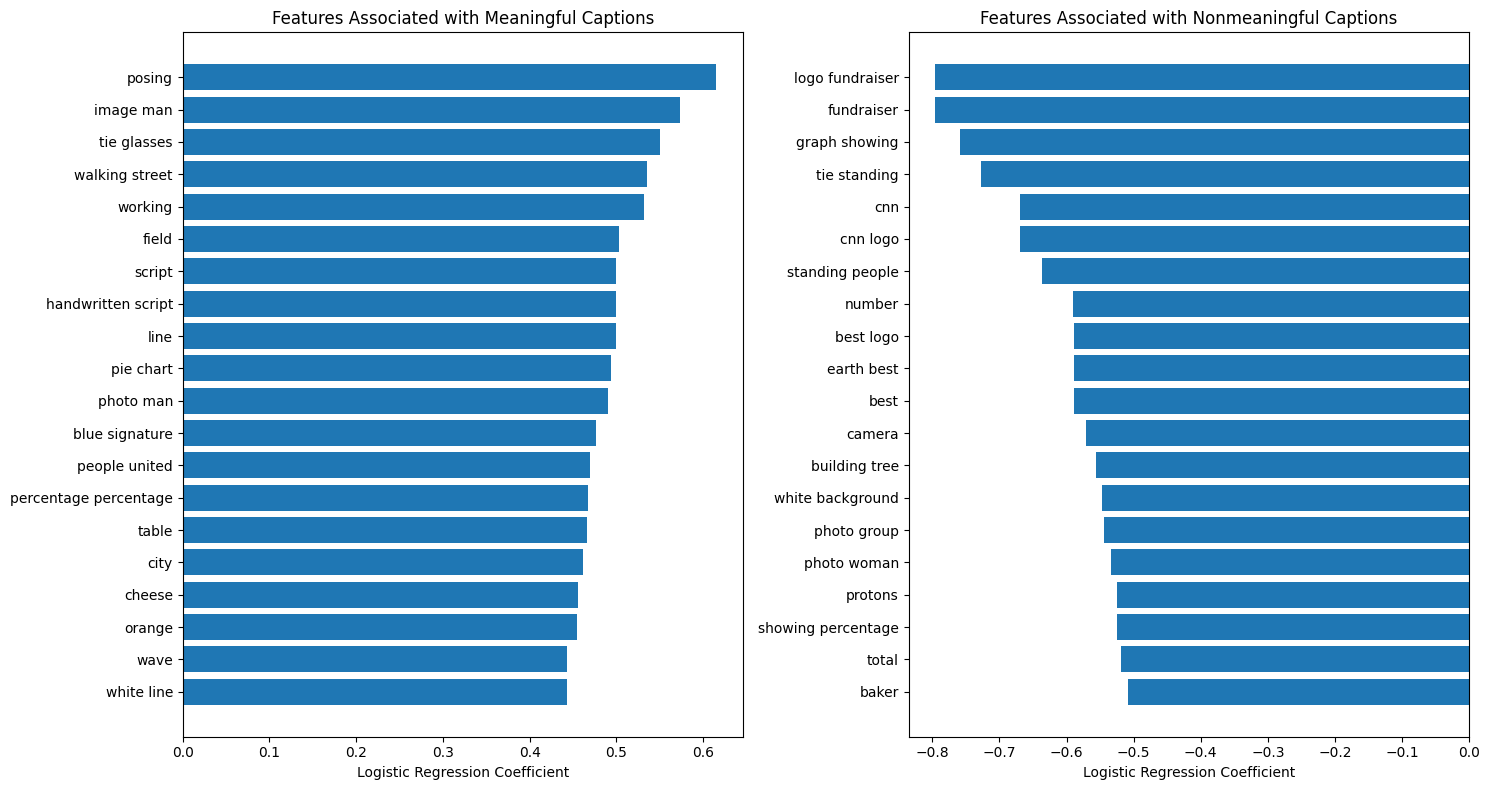

In [16]:
# ============================================================
# 10. FEATURE IMPORTANCE
# ============================================================

feature_names = np.array(
    tfidf_vectorizer.get_feature_names_out()
)

coefficients = logistic_model.coef_[0]

# ------------------------------------------------------------
# TOP POSITIVE FEATURES
# ------------------------------------------------------------

top_positive_indices = np.argsort(
    coefficients
)[-20:][::-1]

top_positive_features = pd.DataFrame({
    "Feature": feature_names[top_positive_indices],
    "Coefficient": coefficients[top_positive_indices]
})

# ------------------------------------------------------------
# TOP NEGATIVE FEATURES
# ------------------------------------------------------------

top_negative_indices = np.argsort(
    coefficients
)[:20]

top_negative_features = pd.DataFrame({
    "Feature": feature_names[top_negative_indices],
    "Coefficient": coefficients[top_negative_indices]
})

print("Top features associated with MEANINGFUL captions:")
display(top_positive_features)

print("\nTop features associated with NONMEANINGFUL captions:")
display(top_negative_features)

# ------------------------------------------------------------
# FEATURE IMPORTANCE VISUALIZATION
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 8)
)

axes[0].barh(
    top_positive_features["Feature"][::-1],
    top_positive_features["Coefficient"][::-1]
)

axes[0].set_title("Features Associated with Meaningful Captions")
axes[0].set_xlabel("Logistic Regression Coefficient")

axes[1].barh(
    top_negative_features["Feature"][::-1],
    top_negative_features["Coefficient"][::-1]
)

axes[1].set_title("Features Associated with Nonmeaningful Captions")
axes[1].set_xlabel("Logistic Regression Coefficient")

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "feature_importance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
# ============================================================
# 11. SAVE TRAINED ARTIFACTS
# ============================================================

# ------------------------------------------------------------
# SAVE LOGISTIC REGRESSION MODEL
# ------------------------------------------------------------

logistic_model_path = os.path.join(
    OUTPUT_DIR,
    "logistic_regression_model.pkl"
)

joblib.dump(
    logistic_model,
    logistic_model_path
)

# ------------------------------------------------------------
# SAVE TF-IDF VECTORIZER
# ------------------------------------------------------------

tfidf_path = os.path.join(
    OUTPUT_DIR,
    "tfidf_vectorizer.pkl"
)

joblib.dump(
    tfidf_vectorizer,
    tfidf_path
)

# ------------------------------------------------------------
# SAVE MODEL CONFIGURATION
# ------------------------------------------------------------

model_config = {
    "model_type": "Logistic Regression",
    "feature_extraction": "TF-IDF",

    "dataset": os.path.basename(DATASET_PATH),

    "random_seed": RANDOM_SEED,

    "split_strategy": split_type,
    "validation_size": VALIDATION_SIZE,

    "tfidf_parameters": {
        "max_features": MAX_FEATURES,
        "ngram_range": list(NGRAM_RANGE),
        "min_df": MIN_DF,
        "max_df": MAX_DF,
        "sublinear_tf": True,
        "stop_words": "english"
    },

    "logistic_regression_parameters": {
        "C": C_VALUE,
        "max_iter": MAX_ITER,
        "class_weight": CLASS_WEIGHT,
        "solver": "liblinear"
    },

    "classification_threshold": 0.5,

    "validation_metrics": {
        "accuracy": float(val_accuracy),
        "precision": float(val_precision),
        "recall": float(val_recall),
        "f1_score": float(val_f1),
        "roc_auc": float(val_roc_auc)
    }
}

config_path = os.path.join(
    OUTPUT_DIR,
    "model_config.json"
)

with open(config_path, "w") as f:

    json.dump(
        model_config,
        f,
        indent=4
    )

# ------------------------------------------------------------
# SAVE VALIDATION METRICS
# ------------------------------------------------------------

metrics_df = pd.DataFrame(
    [
        {
            "Model": "TF-IDF + Logistic Regression",
            "Accuracy": val_accuracy,
            "Precision": val_precision,
            "Recall": val_recall,
            "F1": val_f1,
            "ROC_AUC": val_roc_auc
        }
    ]
)

metrics_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "evaluation_metrics.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# SAVE VALIDATION PREDICTIONS
# ------------------------------------------------------------

predictions_df = val_df.copy()

predictions_df["predicted_label"] = val_predictions

predictions_df["meaningful_probability"] = val_probabilities

predictions_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "validation_predictions.csv"
    ),
    index=False
)

print("Model artifacts saved successfully.")

print("\nSaved files:")

for filename in os.listdir(OUTPUT_DIR):

    print(filename)

Model artifacts saved successfully.

Saved files:
confusion_matrix.png
roc_curve.png
feature_importance.png
logistic_regression_model.pkl
tfidf_vectorizer.pkl
model_config.json
evaluation_metrics.csv
validation_predictions.csv


In [18]:
# ============================================================
# 12. RELOAD SAVED MODEL
# ============================================================

loaded_logistic_model = joblib.load(
    os.path.join(
        OUTPUT_DIR,
        "logistic_regression_model.pkl"
    )
)

loaded_tfidf_vectorizer = joblib.load(
    os.path.join(
        OUTPUT_DIR,
        "tfidf_vectorizer.pkl"
    )
)

# ------------------------------------------------------------
# TEST WITH A NEW CAPTION
# ------------------------------------------------------------

test_caption = [
    "A bar chart comparing student enrollment across five years."
]

test_features = loaded_tfidf_vectorizer.transform(
    test_caption
)

test_prediction = loaded_logistic_model.predict(
    test_features
)[0]

test_probability = loaded_logistic_model.predict_proba(
    test_features
)[0, 1]

print("Caption:", test_caption[0])

print(
    "Predicted class:",
    "Meaningful" if test_prediction == 1 else "Nonmeaningful"
)

print(
    f"Meaningful probability: {test_probability:.4f}"
)

Caption: A bar chart comparing student enrollment across five years.
Predicted class: Meaningful
Meaningful probability: 0.6530
